# Phân tích thực nghiệm N-Queens

- 18 kích thước bàn cờ, 14 cấu hình, mỗi cấu hình chạy 3 lần.
- Giới hạn tổng thời gian: 100 giây/lượt.
- Giới hạn RSS lấy mẫu: 8192 MiB/lượt.
- Các lượt chạy tuần tự, mỗi solver dùng một thread.
- Thời gian và RAM được tổng hợp trên các lượt giải thành công.
- Luôn công bố số lượt timeout, memory limit và error.

## Thay đổi môi trường trong quá trình chạy

239 lượt đầu được thực hiện trước khi cấu hình thêm paging file
trên ổ E và sửa phần dọn tiến trình của bộ giám sát.
517 lượt còn lại được chạy sau thay đổi.

Kết quả trước/sau được giữ dấu vết phiên chạy. Đây là một giới hạn
của thực nghiệm, cần nêu trong báo cáo khi diễn giải thời gian và RAM.

In [5]:
import json
import sys
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

ROOT = Path(r"E:\nqueens-assignment")
EXPERIMENT = ROOT / "results/experiments/20261008T102037Z_10c488e7"

if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from src.evaluation.comparator import is_success

config = json.loads(
    (EXPERIMENT / "config.json").read_text(encoding="utf-8")
)
report = json.loads(
    (EXPERIMENT / "analysis.json").read_text(encoding="utf-8")
)
rows = [
    json.loads(line)
    for line in (EXPERIMENT / "results.jsonl")
    .read_text(encoding="utf-8")
    .splitlines()
    if line.strip()
]

planned = {
    (repeat, n, method)
    for repeat in range(1, config["repeats"] + 1)
    for n in config["sizes"]
    for method in config["methods"]
}
keys = [(r["repeat"], r["n"], r["method"]) for r in rows]

assert len(keys) == len(set(keys)), "Có lượt trùng"
assert set(keys) == planned, "Có lượt thiếu hoặc ngoài kế hoạch"
assert all(
    is_success(r)
    for r in rows
    if r["status"] in ("SAT", "UNSAT")
), "Có kết quả SAT/UNSAT không hợp lệ"

df = pd.DataFrame(rows)
summary = pd.DataFrame(report["groups"])
df["success"] = [is_success(r) for r in rows]
df["session"] = df["resume_session"].fillna("before_restart")

EXPORT = EXPERIMENT / "notebook_analysis"
EXPORT.mkdir(exist_ok=True)

print(f"Đã kiểm tra: {len(df)}/{len(planned)} lượt")
display(df["status"].value_counts().rename("runs").to_frame())

Đã kiểm tra: 756/756 lượt


,runs
status,
SAT,612
TIMEOUT,101
MEMORY_LIMIT,42
ERROR,1


In [6]:
methods = config["methods"]
sizes = config["sizes"]

status_table = pd.crosstab(df["method"], df["status"]).reindex(
    index=methods,
    columns=["SAT", "UNSAT", "TIMEOUT", "MEMORY_LIMIT", "ERROR", "NOT_RUN"],
    fill_value=0,
)

status_table["completed_runs"] = status_table.sum(axis=1)
status_table["success_rate"] = (
    df.groupby("method")["success"].mean().reindex(methods)
)

display(status_table)
display(pd.crosstab(df["session"], df["status"]))

# Các cột mẫu, median và IQR được giữ trong bảng tổng hợp.
summary_columns = [
    "n", "method", "solved", "planned", "failed",
    "total_wall_s_samples",
    "total_wall_s_median", "total_wall_s_iqr",
    "solve_s_median",
    "peak_rss_mib_median", "peak_rss_mib_iqr",
]

display(summary[summary_columns].head(14))

errors = df.loc[
    df["status"] == "ERROR",
    ["n", "method", "repeat", "error", "exit_code", "log_path"],
]
display(errors)

status_table.to_csv(EXPORT / "status_summary.csv", encoding="utf-8-sig")
summary.to_csv(EXPORT / "group_statistics.csv", index=False, encoding="utf-8-sig")
errors.to_csv(EXPORT / "errors.csv", index=False, encoding="utf-8-sig")

status,SAT,UNSAT,TIMEOUT,MEMORY_LIMIT,ERROR,NOT_RUN,completed_runs,success_rate
method,,,,,,,,
glucose3:binomial,39,0,0,15,0,0,54,0.722222
glucose3:binary,45,0,3,6,0,0,54,0.833333
glucose3:commander,54,0,0,0,0,0,54,1.000000
glucose3:product,21,0,33,0,0,0,54,0.388889
glucose3:sequential,33,0,21,0,0,0,54,0.611111
cadical195:binomial,39,0,0,15,0,0,54,0.722222
cadical195:binary,48,0,0,5,1,0,54,0.888889
cadical195:commander,51,0,2,1,0,0,54,0.944444
cadical195:product,48,0,6,0,0,0,54,0.888889


status,ERROR,MEMORY_LIMIT,SAT,TIMEOUT
session,,,,
20261008T124718_080081Z,0,32,411,74
before_restart,1,10,201,27


,n,method,solved,planned,failed,total_wall_s_samples,total_wall_s_median,total_wall_s_iqr,solve_s_median,peak_rss_mib_median,peak_rss_mib_iqr
0,4,glucose3:binomial,3,3,0,3,0.188573,0.026391,0.000022,31.457031,2.031250
1,4,glucose3:binary,3,3,0,3,0.183939,0.005137,0.000026,32.105469,0.537109
2,4,glucose3:commander,3,3,0,3,0.180573,0.003784,0.000023,32.214844,1.449219
3,4,glucose3:product,3,3,0,3,0.180961,0.001461,0.000022,32.199219,0.650391
4,4,glucose3:sequential,3,3,0,3,0.180340,0.003184,0.000030,32.339844,0.453125
5,4,cadical195:binomial,3,3,0,3,0.179956,0.002206,0.000038,31.906250,0.740234
6,4,cadical195:binary,3,3,0,3,0.177891,0.002887,0.000037,31.980469,0.222656
7,4,cadical195:commander,3,3,0,3,0.181462,0.002473,0.000040,32.601562,0.154297
8,4,cadical195:product,3,3,0,3,0.184442,0.003136,0.000034,32.187500,1.283203
9,4,cadical195:sequential,3,3,0,3,0.178820,0.005532,0.000037,32.300781,0.361328


,n,method,repeat,error,exit_code,log_path
230,1000,cadical195:binary,1,Tiến trình lỗi; xem solver.log,3221226505,E:\nqueens-assignment\results\experiments\2026...


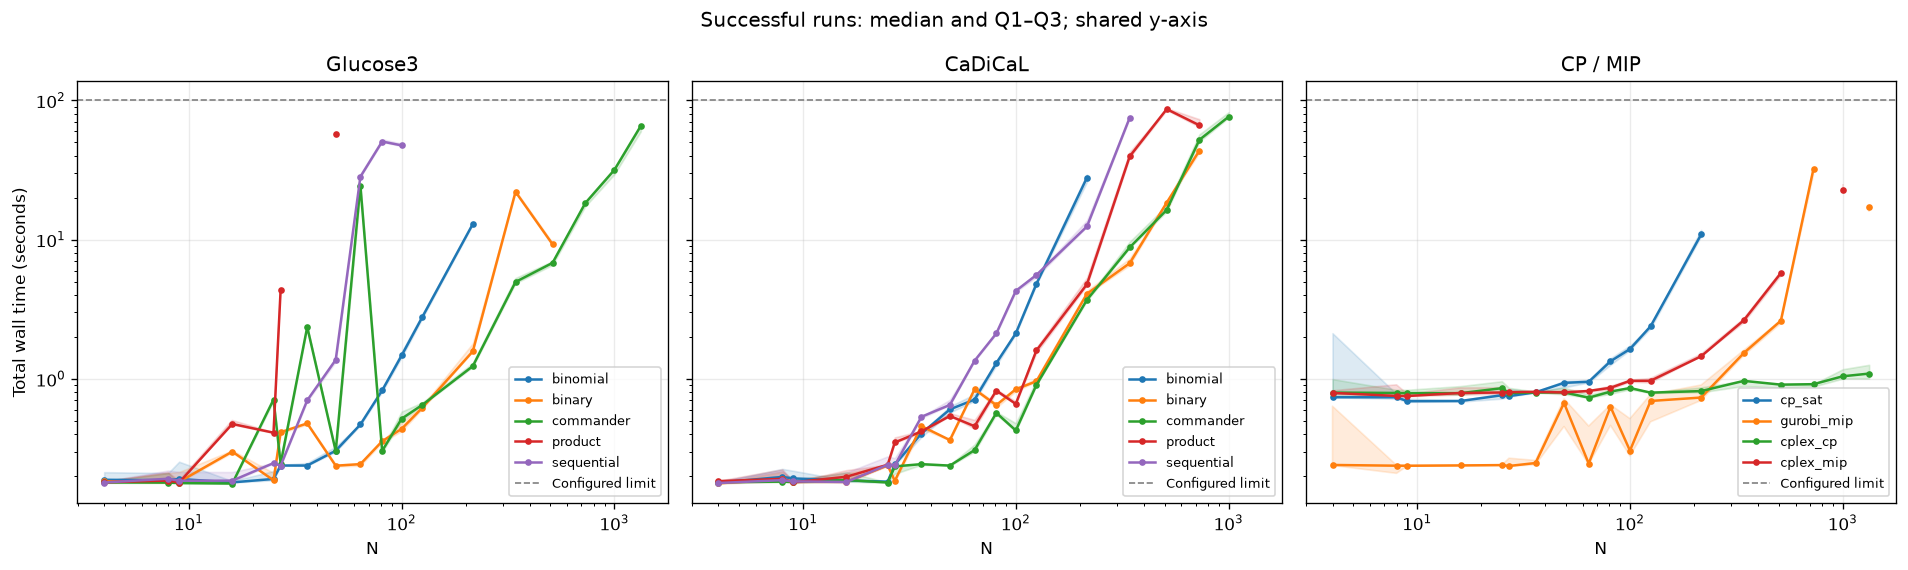

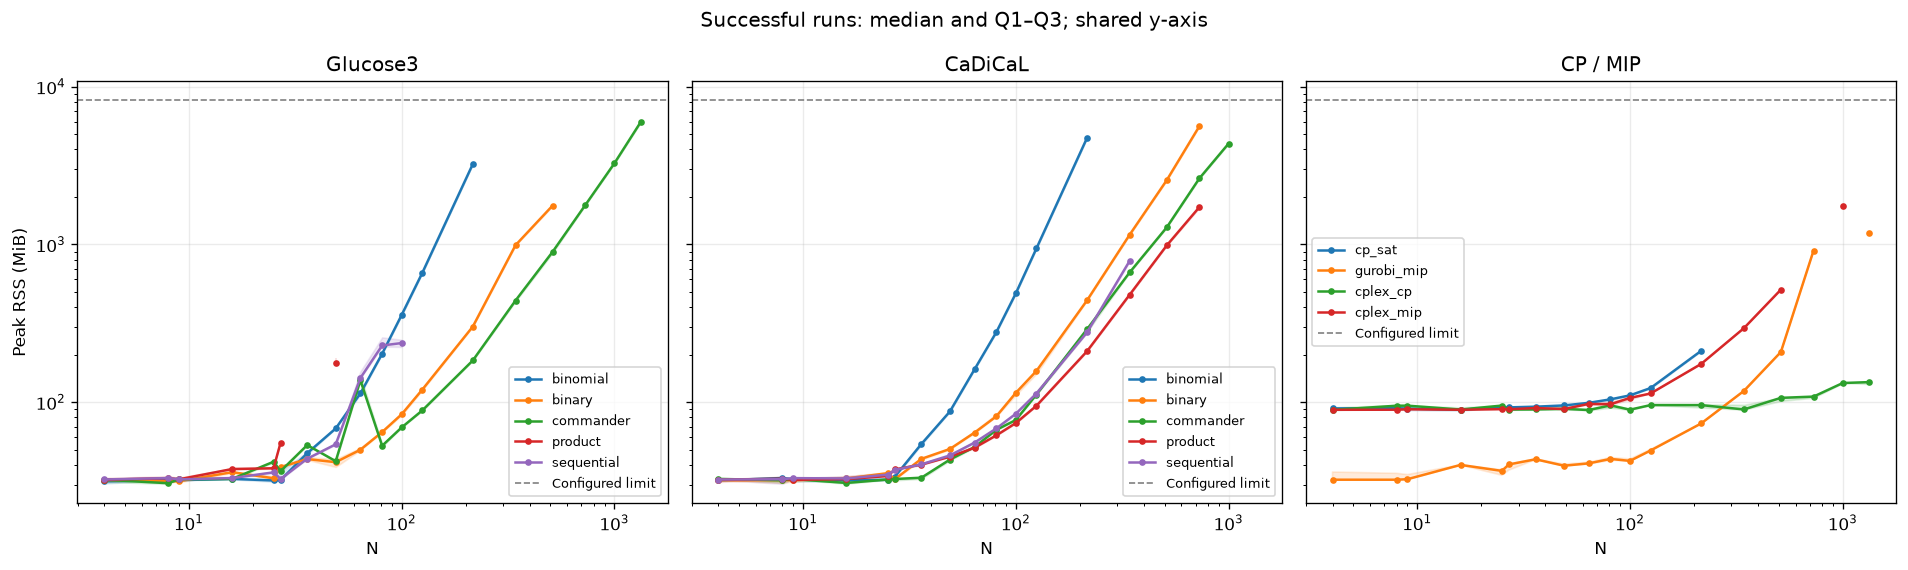

In [7]:
plt.rcParams.update({
    "figure.dpi": 120,
    "font.size": 10,
    "axes.grid": True,
    "grid.alpha": 0.25,
})

panels = {
    "Glucose3": [m for m in methods if m.startswith("glucose3:")],
    "CaDiCaL": [m for m in methods if m.startswith("cadical195:")],
    "CP / MIP": [m for m in methods if ":" not in m],
}

successful = df.loc[df["success"]].copy()


def plot_metric(metric, ylabel, filename, limit):
    fig, axes = plt.subplots(
        1, 3,
        figsize=(16, 4.8),
        sharex=True,
        sharey=True,
    )

    for ax, (title, selected) in zip(axes, panels.items()):
        for method in selected:
            values = successful.loc[
                successful["method"] == method
            ]

            stats = (
                values.groupby("n")[metric]
                .agg(
                    median="median",
                    q1=lambda s: s.quantile(0.25),
                    q3=lambda s: s.quantile(0.75),
                    samples="count",
                )
                .reindex(sizes)
            )

            line, = ax.plot(
                sizes,
                stats["median"],
                marker="o",
                markersize=3,
                label=method.split(":")[-1],
            )

            # Chỉ vẽ vùng tứ phân vị khi có ít nhất hai mẫu.
            has_iqr = stats["samples"].ge(2)

            ax.fill_between(
                sizes,
                stats["q1"].where(has_iqr).to_numpy(dtype=float),
                stats["q3"].where(has_iqr).to_numpy(dtype=float),
                color=line.get_color(),
                alpha=0.15,
            )

            partial = stats.loc[
                stats["samples"].gt(0)
                & stats["samples"].lt(config["repeats"])
            ]

            ax.scatter(
                partial.index,
                partial["median"],
                facecolors="white",
                edgecolors=line.get_color(),
                s=40,
                zorder=4,
            )

            for n, row in partial.iterrows():
                ax.annotate(
                    f"{int(row['samples'])}/{config['repeats']}",
                    (n, row["median"]),
                    xytext=(4, 5),
                    textcoords="offset points",
                    fontsize=7,
                )

        ax.axhline(
            limit,
            color="gray",
            linestyle="--",
            linewidth=1,
            label="Configured limit",
        )

        ax.set_xscale("log")
        ax.set_yscale("log")
        ax.set_title(title)
        ax.set_xlabel("N")
        ax.legend(fontsize=8)

    axes[0].set_ylabel(ylabel)
    fig.suptitle(
        "Successful runs: median and Q1–Q3; shared y-axis"
    )
    fig.tight_layout()
    fig.savefig(EXPORT / f"{filename}.png", bbox_inches="tight")
    fig.savefig(EXPORT / f"{filename}.pdf", bbox_inches="tight")
    plt.show()


plot_metric(
    "total_wall_s",
    "Total wall time (seconds)",
    "runtime",
    config["wall_limit_s"],
)

plot_metric(
    "peak_rss_mib",
    "Peak RSS (MiB)",
    "memory",
    config["memory_limit_mib"],
)

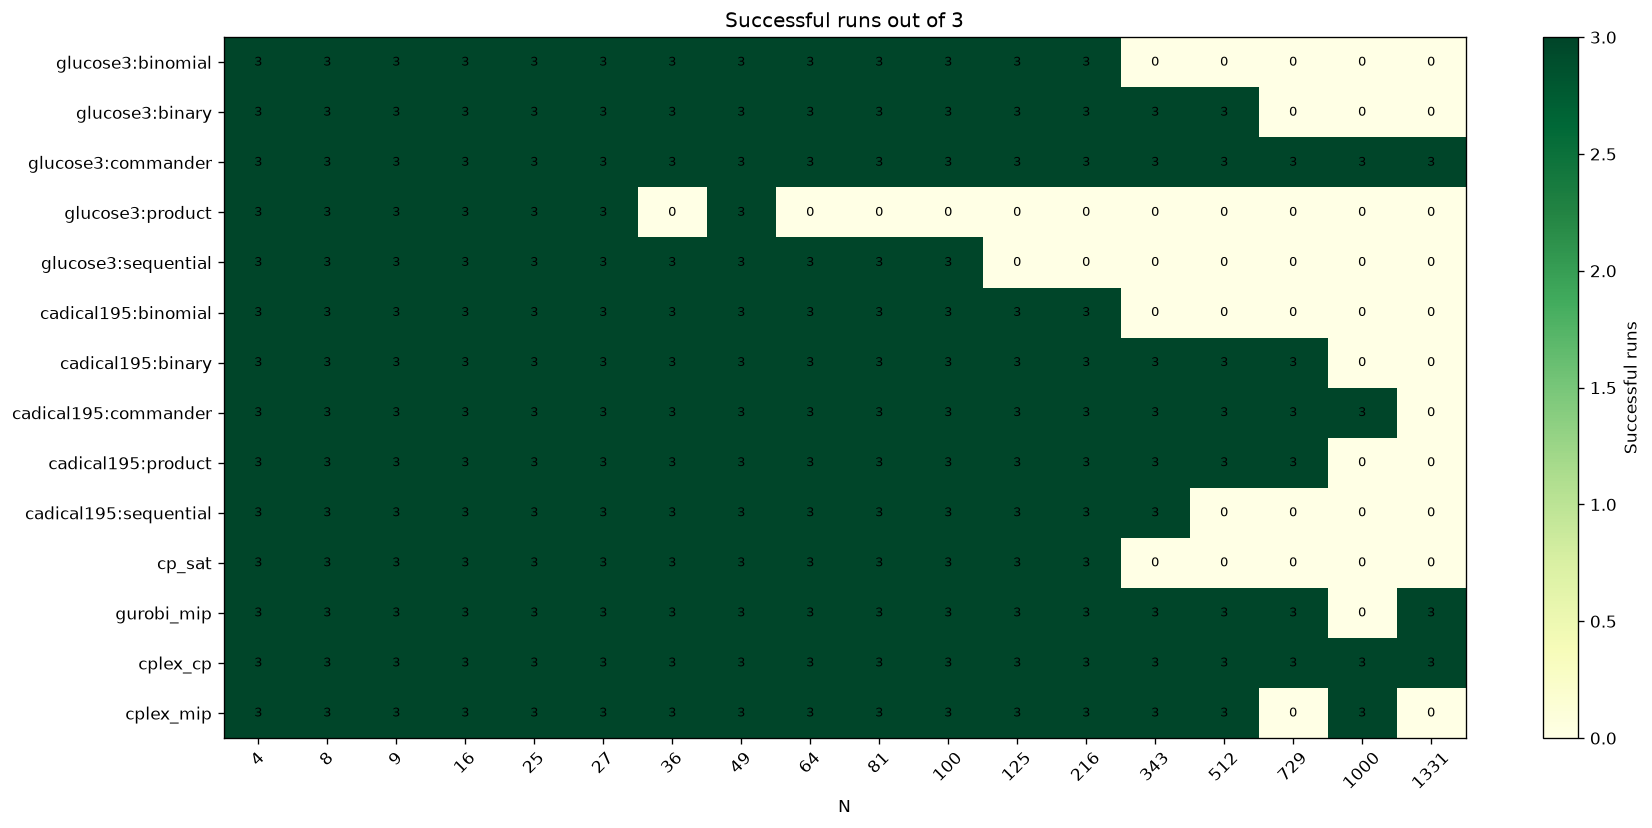

Đã xuất bảng và biểu đồ tại: E:\nqueens-assignment\results\experiments\20261008T102037Z_10c488e7\notebook_analysis


In [8]:
solved_table = (
    summary.pivot(index="method", columns="n", values="solved")
    .reindex(index=methods, columns=sizes)
)

fig, ax = plt.subplots(figsize=(15, 7))
image = ax.imshow(
    solved_table.to_numpy(),
    aspect="auto",
    vmin=0,
    vmax=config["repeats"],
    cmap="YlGn",
)

ax.set_xticks(range(len(sizes)), labels=sizes, rotation=45)
ax.set_yticks(range(len(methods)), labels=methods)
ax.set_xlabel("N")
ax.set_title(f"Successful runs out of {config['repeats']}")
ax.grid(False)

for i in range(len(methods)):
    for j in range(len(sizes)):
        ax.text(
            j, i, str(int(solved_table.iloc[i, j])),
            ha="center", va="center", fontsize=8,
        )

fig.colorbar(image, ax=ax, label="Successful runs")
fig.tight_layout()
fig.savefig(EXPORT / "success_counts.png", bbox_inches="tight")
fig.savefig(EXPORT / "success_counts.pdf", bbox_inches="tight")
plt.show()

solved_table.to_csv(
    EXPORT / "success_counts.csv",
    encoding="utf-8-sig",
)

print("Đã xuất bảng và biểu đồ tại:", EXPORT)

## Kích thước mô hình SAT

Số biến và clause được tính từ chi phí của từng nhóm AMO:

- Có 2N nhóm hàng/cột, mỗi nhóm dài N.
- Hai đường chéo dài N.
- Với mỗi độ dài từ 2 đến N−1, có bốn đường chéo.
- Có 2N clause ALO cho hàng/cột.
- Đường chéo chỉ có AMO.

Không dựng toàn bộ CNF lớn. Với các encoder dùng biến phụ,
chỉ sinh AMO của từng độ dài để đếm chi phí.
Binomial dùng công thức m(m−1)/2 clause.

Các số đếm này mô tả kích thước CNF do thuật toán tạo ra,
không phải số clause sau tiền xử lý của solver.
Chúng được đối chiếu với các thông số CNF đã lưu trong benchmark.

In [9]:
from collections import Counter
from functools import lru_cache
from importlib import import_module

encoding_names = [
    "binomial",
    "binary",
    "commander",
    "product",
    "sequential",
]

encoders = {
    name: import_module(
        "src.encodings."
        + ("sequential_counter" if name == "sequential" else name)
    ).encode_amo
    for name in encoding_names
}


@lru_cache(maxsize=None)
def amo_size(encoding, m):
    """Trả về số clause và biến phụ của một nhóm AMO."""
    if m <= 1:
        return 0, 0

    if encoding == "binomial":
        return m * (m - 1) // 2, 0

    clauses, top_id = encoders[encoding](
        list(range(1, m + 1)),
        m,
    )
    return len(clauses), top_id - m


model_rows = []

for n in sizes:
    group_lengths = Counter({n: 2 * n})

    for m in range(2, n + 1):
        group_lengths[m] += 2 if m == n else 4

    for encoding in encoding_names:
        clauses = 2 * n
        auxiliary = 0

        for m, multiplicity in group_lengths.items():
            group_clauses, group_auxiliary = amo_size(encoding, m)
            clauses += multiplicity * group_clauses
            auxiliary += multiplicity * group_auxiliary

        model_rows.append({
            "n": n,
            "encoding": encoding,
            "base_variables": n * n,
            "aux_variables": auxiliary,
            "max_variable_id": n * n + auxiliary,
            "cnf_clauses": clauses,
        })

model_sizes = pd.DataFrame(model_rows)

fields = [
    "base_variables",
    "aux_variables",
    "max_variable_id",
    "cnf_clauses",
]

expected_sizes = model_sizes.set_index(["n", "encoding"])
checked = 0

for record in rows:
    encoding = record.get("encoding")

    if encoding not in encoding_names:
        continue

    if not all(record.get(field) is not None for field in fields):
        continue

    expected = expected_sizes.loc[(record["n"], encoding)]

    assert all(
        record[field] == int(expected[field])
        for field in fields
    ), (
        f"Số đếm không khớp: N={record['n']}, "
        f"encoding={encoding}"
    )

    checked += 1

print(f"Đã tính {len(model_sizes)} mô hình.")
print(f"Đối chiếu khớp {checked} bản ghi benchmark.")

display(model_sizes.loc[model_sizes["n"] == max(sizes)])

model_sizes.to_csv(
    EXPORT / "cnf_sizes.csv",
    index=False,
    encoding="utf-8-sig",
)

Đã tính 90 mô hình.
Đối chiếu khớp 420 bản ghi benchmark.


,n,encoding,base_variables,aux_variables,max_variable_id,cnf_clauses
85,1331,binomial,1771561,0,1771561,3926372802
86,1331,binary,1771561,79636,1851197,75151050
87,1331,commander,1771561,3555340,5326901,24787642
88,1331,product,1771561,765004,2536565,15533774
89,1331,sequential,1771561,7078260,8849821,21229462


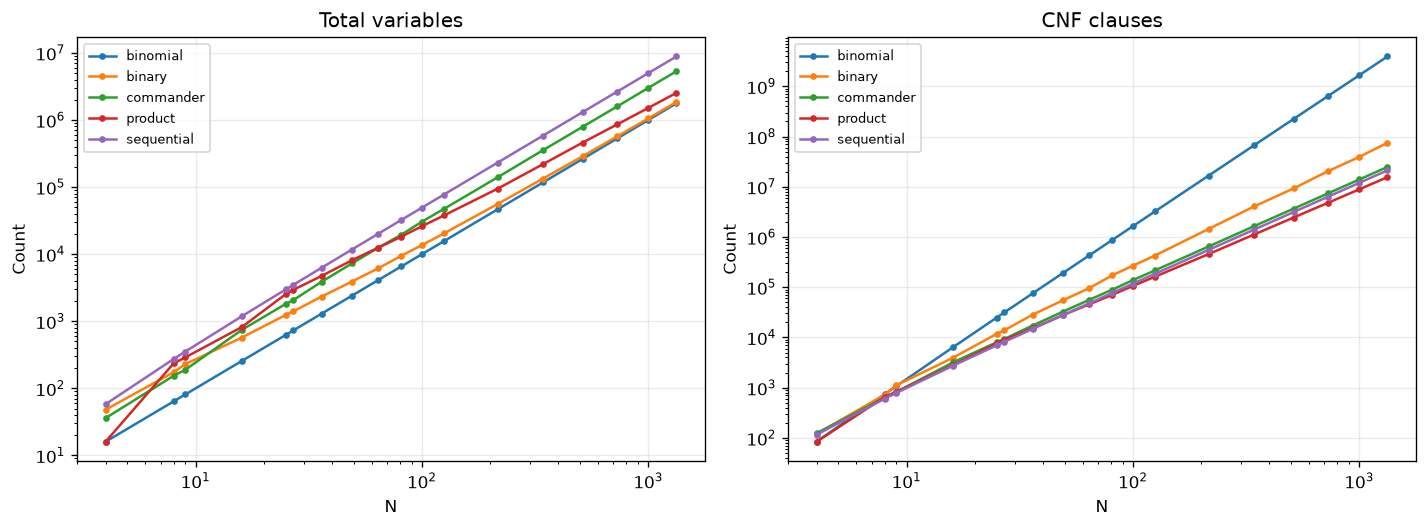

encoding,binomial,binary,commander,product,sequential
n,,,,,
4,84,120,124,84,116
8,744,728,634,652,604
9,1074,1114,822,826,786
16,6352,3928,3176,2804,2732
25,24850,11806,8018,7638,6962
27,31410,13890,9294,8930,8166
36,75252,28320,17276,15292,14772
49,191394,54866,32526,27742,27746
64,428864,95576,55990,45620,47756


In [10]:
fig, axes = plt.subplots(
    1, 2,
    figsize=(12, 4.5),
    sharex=True,
)

metrics = [
    ("max_variable_id", "Total variables"),
    ("cnf_clauses", "CNF clauses"),
]

for ax, (metric, title) in zip(axes, metrics):
    for encoding in encoding_names:
        group = (
            model_sizes.loc[
                model_sizes["encoding"] == encoding
            ]
            .sort_values("n")
        )

        ax.plot(
            group["n"],
            group[metric],
            marker="o",
            markersize=3,
            label=encoding,
        )

    ax.set_xscale("log")
    ax.set_yscale("log")
    ax.set_xlabel("N")
    ax.set_ylabel("Count")
    ax.set_title(title)
    ax.legend(fontsize=8)

fig.tight_layout()
fig.savefig(EXPORT / "cnf_sizes.png", bbox_inches="tight")
fig.savefig(EXPORT / "cnf_sizes.pdf", bbox_inches="tight")
plt.show()

clause_table = (
    model_sizes.pivot(
        index="n",
        columns="encoding",
        values="cnf_clauses",
    )
    .reindex(index=sizes, columns=encoding_names)
)

display(clause_table)

## Nhận xét và giới hạn

- Glucose3 + Commander và CPLEX CP giải thành công toàn bộ 54 lượt.
- Binomial trên cả hai SAT solver chạm giới hạn RAM ở năm
  kích thước lớn nhất.
- Product đạt 21/54 lượt thành công với Glucose3 và 48/54 với CaDiCaL.
  Hiệu năng phụ thuộc cả encoder và solver.
- Thời gian không tăng đều theo N: Gurobi timeout tại N=1000
  nhưng giải được N=1331.
- Biểu đồ thời gian/RAM chỉ tổng hợp các lượt thành công,
  phải đọc cùng bảng trạng thái và heatmap.
- Total wall time gồm khởi động tiến trình, import thư viện,
  dựng mô hình, giải và xử lý kết quả.
- RSS được lấy mẫu mỗi 50 ms, có thể bỏ sót đỉnh ngắn;
  giới hạn RAM không phải giới hạn cứng do hệ điều hành áp đặt.
- Mỗi nhóm chỉ có ba lần lặp, dùng seed mặc định của solver.
- Paging file và phần dọn tiến trình thay đổi sau 239 lượt đầu.
  Không suy ra tác động riêng của thay đổi này từ dữ liệu hiện có.
- Một lượt CaDiCaL + Binary tại N=1000 kết thúc bất thường;
  giữ nguyên trạng thái ERROR.